In [46]:
# load libraries
import requests
import zipfile
import io
import duckdb
import pandas as pd
import numpy as np
import polars as pl
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

In [35]:
# data loading
project_root = Path.cwd()
data_dir = project_root / "data"
listings_df = pd.read_csv(data_dir / "listings.csv.gz")
reviews_df = pd.read_csv(data_dir / "reviews.csv.gz")
calender_df = pd.read_csv(data_dir / "calendar.csv.gz")
ngh_df = gpd.read_file(data_dir / "neighbourhoods.geojson")

/var/folders/qb/pd0pzd3x0jj2c_2nkn2hmrxw0000gn/T/ipykernel_54362/3067976704.py:4: DtypeWarning: Columns (4: source) have mixed types. Specify dtype option on import or set low_memory=False.
  listings_df = pd.read_csv(data_dir / "listings.csv.gz")


In [36]:
listings_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 91954 entries, 0 to 91953
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            91954 non-null  int64  
 1   listing_url                                   91954 non-null  str    
 2   scrape_id                                     91954 non-null  int64  
 3   last_scraped                                  91954 non-null  str    
 4   source                                        32311 non-null  str    
 5   name                                          91954 non-null  str    
 6   description                                   91253 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   91949 non-null  str    
 9   host_id                                       91954 non-null  int64  
 1

In [37]:
reviews_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2323969 entries, 0 to 2323968
Data columns (total 6 columns):
 #   Column         Dtype
---  ------         -----
 0   listing_id     int64
 1   id             int64
 2   date           str  
 3   reviewer_id    int64
 4   reviewer_name  str  
 5   comments       str  
dtypes: int64(3), str(3)
memory usage: 106.4 MB


In [38]:
calender_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33563890 entries, 0 to 33563889
Data columns (total 5 columns):
 #   Column          Dtype
---  ------          -----
 0   listing_id      int64
 1   date            str  
 2   available       str  
 3   minimum_nights  int64
 4   maximum_nights  int64
dtypes: int64(3), str(2)
memory usage: 1.3 GB


In [39]:
ngh_df.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   neighbourhood        33 non-null     str     
 1   neighbourhood_group  0 non-null      object  
 2   geometry             33 non-null     geometry
dtypes: geometry(1), object(1), str(1)
memory usage: 924.0+ bytes


In [72]:
# count the number of unique listings with non-null price attribute
temp_df = listings_df.copy()
temp_df = temp_df[["id", "price"]]
temp_df = temp_df[temp_df["price"].notna()]
print(temp_df["id"].nunique())

# log transform the listing price
temp_df["price"] = temp_df["price"].str.replace("$", "")
temp_df["price"] = temp_df["price"].str.replace(",", "").astype(float)
temp_df["log_price"] = np.log(temp_df["price"])

# drop prices exceeding the 99th percentile
temp_df = temp_df[temp_df["price"] <= temp_df["price"].quantile(0.99)]

59905


Text(0.5, 0.98, 'Distribution of Price and Log Price')

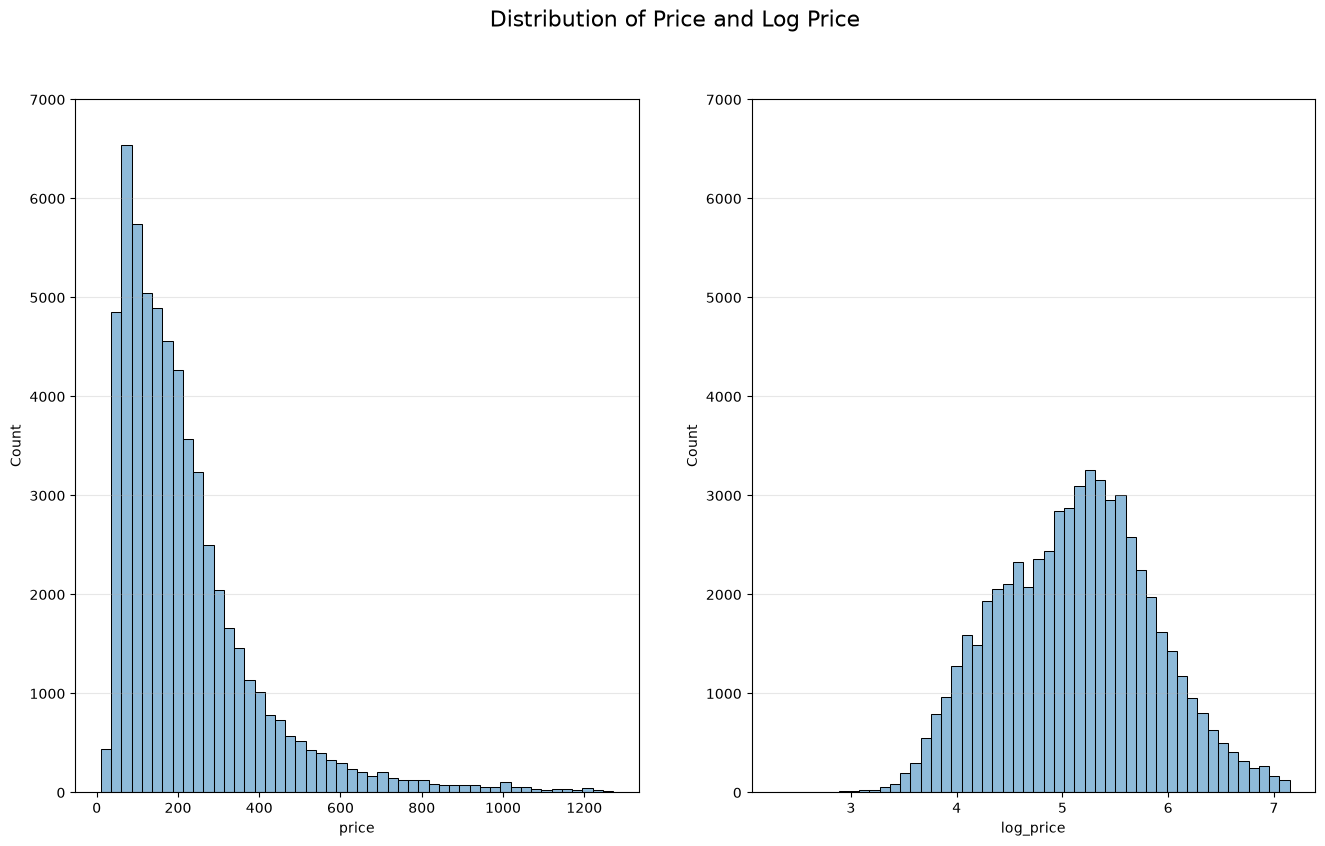

In [76]:
# plot the distribution of listing price
fig, axes = plt.subplots(1, 2, figsize = (16, 9))

sns.histplot(
        data = temp_df,
        x = "price",
        bins = 50,
        stat = "count",
        alpha = 0.5,
        ax = axes[0]
    )

sns.histplot(
        data = temp_df,
        x = "log_price",
        bins = 50,
        stat = "count",
        alpha = 0.5,
        ax = axes[1]
    )

for ax in axes:
     ax.set_ylim(0, 7000)
     ax.grid(axis = "y", alpha = 0.3)

fig.suptitle(
    "Distribution of Price and Log Price",
    fontsize = 16
)